# Task 5: Sales Data Analysis

## Objective
The objective of this project is to analyze Superstore sales data to understand business performance, identify monthly sales trends, find top-selling products, and evaluate profitability.

Sales analysis helps businesses understand revenue patterns, identify popular products, and make informed decisions. In this project, I will use Python and data visualization techniques to analyze sales data and present meaningful business insights.

In this step, I will import the Python libraries required for data analysis and visualization. Pandas will help manipulate the dataset, while Matplotlib and Seaborn will help create charts to understand sales patterns.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

in this step we import kaggle datasetThe Superstore dataset contains information about customer orders, products, sales, dates, and profits. I will upload the CSV file downloaded from Kaggle and load it into a Pandas DataFrame for analysis.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore (1).csv


After uploading the CSV file, I will load it into a Pandas DataFrame. The first five rows will help me understand the structure of the dataset and identify the columns available for analysis.

In [ ]:
filename = next(iter(uploaded))

df = pd.read_csv(filename, encoding="latin1")

print("Dataset loaded successfully!")
print("Filename:", filename)
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Filename: Sample - Superstore (1).csv
Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In this step, I will inspect the dataset to understand its structure, identify column names, check data types, and find missing values. This will help me determine whether any data cleaning is required before performing the analysis.

In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 

Data cleaning improves the quality and reliability of analysis. In this step, I will remove duplicate records, convert the order date into the correct date format, and ensure that sales and profit values are numeric. I will also check for missing values in the important columns used for analysis.

In [ ]:
df = df.copy()
df = df.drop_duplicates()

df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")

df = df.dropna(subset=["Order Date", "Sales", "Profit"])

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)
print("\nMissing values in important columns:")
print(df[["Order Date", "Sales", "Profit"]].isnull().sum())

df.head()

Data cleaning completed!
Cleaned dataset shape: (9994, 21)

Missing values in important columns:
Order Date    0
Sales         0
Profit        0
dtype: int64


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Monthly revenue analysis helps identify changes in sales over time. In this step, I will group sales by month and visualize the revenue trend to understand how business performance changes throughout the year.

Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160
2017-

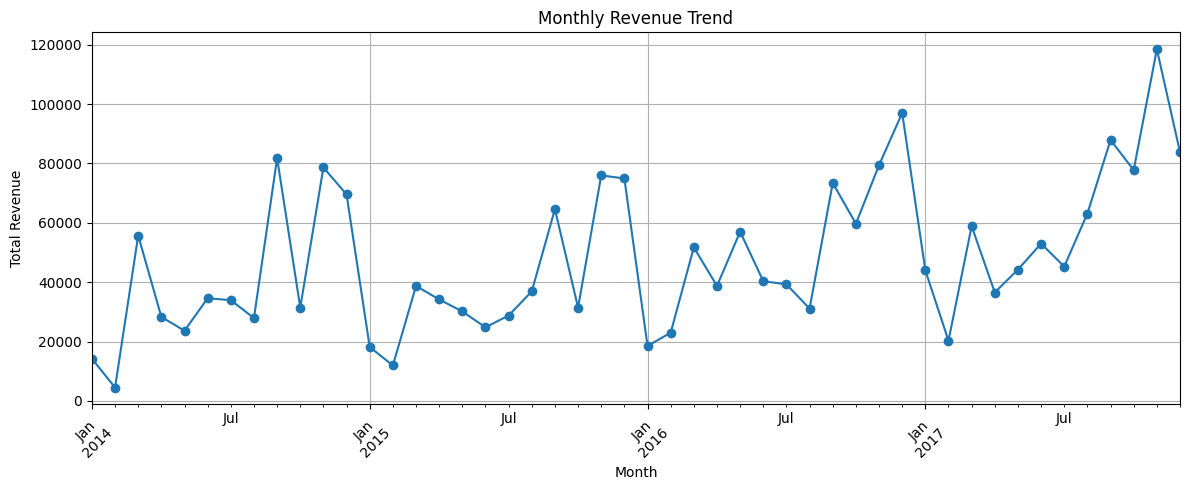

In [ ]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Sales"].sum()

print(monthly_revenue)

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Identifying top-selling products helps a business understand which products generate the highest sales. In this step, I will calculate total sales for each product and visualize the five products with the highest sales revenue.

Top 5 Products by Sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
Name: Sales, dtype: float64


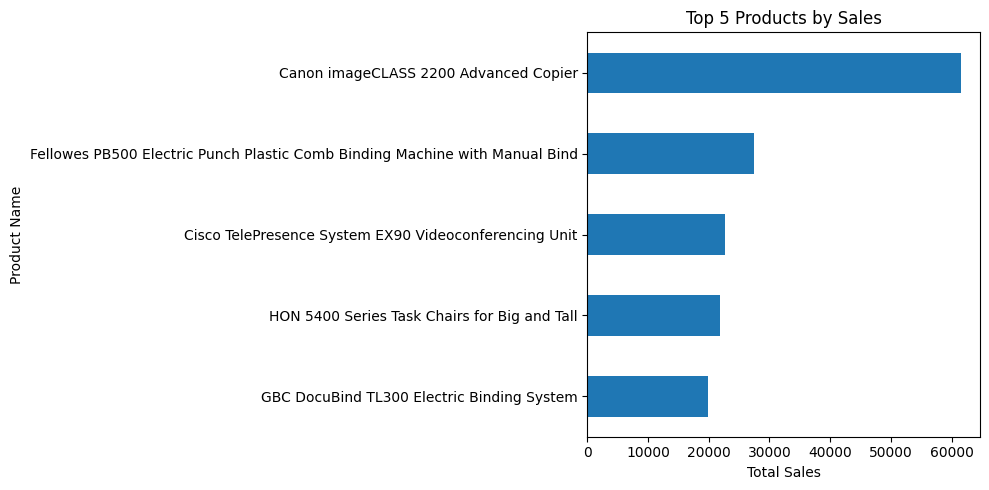

In [ ]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 Products by Sales:")
print(top_products)

plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind="barh")

plt.title("Top 5 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

Sales revenue alone does not show whether a business is profitable. Profitability analysis helps identify which product categories generate the most profit and which may require improvement. In this step, I will calculate and compare total profit across product categories.

Profit by Category:
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


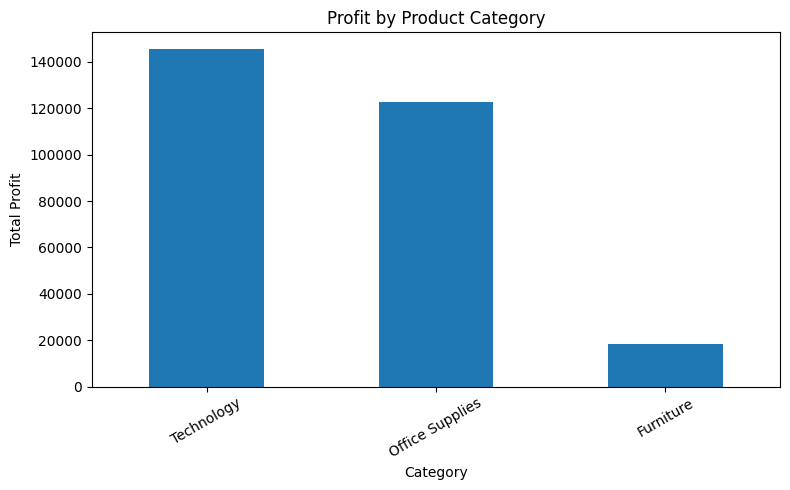

In [ ]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Category:")
print(category_profit)

plt.figure(figsize=(8, 5))
category_profit.plot(kind="bar")

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In this final analysis step, I will summarize total sales, total profit, the month with the highest revenue, and the product with the highest sales. These results will help communicate the main findings of the project clearly.

In [ ]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

best_month = monthly_revenue.idxmax()
best_month_revenue = monthly_revenue.max()

best_product = top_products.idxmax()
best_product_sales = top_products.max()

print("===== SUPERSTORE SALES ANALYSIS =====")
print(f"Total Sales Revenue: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Highest Revenue Month: {best_month}")
print(f"Revenue in Highest Month: {best_month_revenue:,.2f}")
print(f"Top-Selling Product: {best_product}")
print(f"Sales of Top Product: {best_product_sales:,.2f}")

===== SUPERSTORE SALES ANALYSIS =====
Total Sales Revenue: 2,297,200.86
Total Profit: 286,397.02
Highest Revenue Month: 2017-11
Revenue in Highest Month: 118,447.82
Top-Selling Product: Canon imageCLASS 2200 Advanced Copier
Sales of Top Product: 61,599.82


##  Conclusion

In this project, I analyzed the Superstore sales dataset using Python, Pandas, Matplotlib, and Seaborn. I inspected and cleaned the data, examined monthly revenue trends, identified the top-selling products, and compared profitability across product categories.

The visualizations and summary statistics provide insights into sales performance and profitability. These findings can help businesses understand revenue patterns, identify successful products, and make more informed business decisions.